<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Strike counts and scorecards tell different stories

Does the fighter who lands more significant strikes lead every judge's card? We will examine Navajo Stirling versus Ivan Erslan at UFC 315, reconcile round statistics with whole-fight totals, and compare the counts with the judges' actual point margins. A count of strikes and an awarded score are different measurements; this example makes that difference visible without treating either as a complete explanation of the fight.

**Default: recorded actual public response**, not a synthetic fixture. The [UFC live-data feed document for fight 12000](https://d29dxerjsp82wz.cloudfront.net/api/v3/fight/live/12000.json) was captured **2026-11-14 at 10:54:33.970 UTC**. The real Git-tagged worker reads those exact bytes through its supported endpoint override. Live mode reads the same historical resource afresh and never falls back. UFC has no published open-data licence; this limited factual example is unaffiliated with UFC. The event start label in the document is a separate clock from the capture time, and is not this bout's exact start time.

## Choose the round prefix

`LAST_ROUND` is an integer from **1 to 3**, inclusive: retain rounds **1 through LAST_ROUND** after materializing the complete fight. Default **3** includes all rounds; the experiment uses **1**. `DATA_MODE` is **`"replay"`** or **`"live"`**. Both read exactly one fixed fight document. A local round filter does not reduce network requests.

Restart Kernel → Run All after editing. The source fight id stays fixed because another fight could have different coverage, duration, or no judges' scorecards. A prefix is a retrospective view, not a live prediction or an alternative final result.

In [1]:
LAST_ROUND = 3  # integer 1..3, inclusive; experiment: 1
DATA_MODE = "replay"  # replay or live; no fallback

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path
from tempfile import TemporaryDirectory

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

from recorded_api import RecordedAPI

assert type(LAST_ROUND) is int and 1 <= LAST_ROUND <= 3
assert DATA_MODE in {"replay", "live"}
run_utc = datetime.now(UTC).isoformat()
manifest = json.loads(Path("recordings/manifest.json").read_text())["responses"][0]
api = RecordedAPI(Path("recordings"), DATA_MODE, Path("artifacts"))
endpoint_keys = ["UFC_FEED_BASE_URL", "ESPN_SITE_BASE_URL", "ESPN_COMMON_BASE_URL", "UFC_WEB_BASE_URL"]
previous = {key: os.environ.get(key) for key in endpoint_keys}
for key in endpoint_keys:
    os.environ[key] = api.url
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
colors = {"Red": "#c64645", "Blue": "#2878ae", "Tied": "#b0b0b0"}


def prose(text):
    display(Markdown(text))


def finish(fig, top=0.91):
    fig.text(
        0.01,
        0.01,
        f"UFC live-data feed · fight 12000 · event 2025-05-10 UTC · {DATA_MODE} · rounds 1–{LAST_ROUND}",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, top))
    plt.show()


secret_directory = TemporaryDirectory(prefix="ufc-notebook-secrets-")
con = haybarn.connect(config={"secret_directory": secret_directory.name, "allow_persistent_secrets": False})
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ufc/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-ufc/notebooks/pyproject.toml.

## Read one fight through three worker tables

This literal launch uses remote tag `v0.2.0` and the notebook's tested dependency constraints; it needs no worker checkout. `fight_stats`, `fight_round_stats` and `fight_scorecards` reuse one cached response. The helper admits only that document and one read; all other paths fail. We materialize the complete tables before capturing DataFrames, so plotting and local queries cannot repeat the source call.

UFC feed ids differ from ESPN ids. Here `fight_id=12000`, `event_id=1252`, and fighter ids are all from the UFC feed; names are labels, not join keys.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ufc' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-ufc.git@v0.2.0 --constraints worker-constraints.txt vgi-ufc'
);
CREATE TABLE fight_totals AS SELECT * FROM ufc.fight_stats(12000);
CREATE TABLE all_rounds AS SELECT * FROM ufc.fight_round_stats(12000);
CREATE TABLE all_scorecards AS SELECT * FROM ufc.fight_scorecards(12000);
CREATE TABLE selected_rounds AS SELECT * FROM all_rounds WHERE round_number BETWEEN 1 AND {{LAST_ROUND}};
CREATE TABLE selected_scorecards AS SELECT * FROM all_scorecards WHERE round_number BETWEEN 1 AND {{LAST_ROUND}};

,Count


In [4]:
audit = json.loads(Path("artifacts/request-audit.json").read_text())
assert len(audit) == 1 and audit[0]["status"] == 200
payload = json.loads(Path("artifacts/fight-12000.json").read_text())["LiveFightDetail"]
source_time = manifest["retrieved_at_utc"] if DATA_MODE == "replay" else audit[0]["received_utc"]
frames = {
    table: con.execute(f"SELECT * FROM {table} ORDER BY ALL").df()
    for table in ["fight_totals", "all_rounds", "all_scorecards"]
}
fingerprint = hashlib.sha256(
    "".join(frame.to_json(orient="records", date_format="iso") for frame in frames.values()).encode()
).hexdigest()
red_name = frames["fight_totals"].query("corner == 'Red'").fighter_name.iloc[0]
blue_name = frames["fight_totals"].query("corner == 'Blue'").fighter_name.iloc[0]
assert frames["fight_totals"].event_id.eq(payload["Event"]["EventId"]).all()
prose(
    f"**{payload['Event']['Name']}** · event start `{payload['Event']['StartTime']}` (UTC) · feed status **{payload['Status']}**. Red: **{red_name}**; blue: **{blue_name}**. The worker materialized **{len(frames['fight_totals'])} fighter totals**, **{len(frames['all_rounds'])} fighter-round rows** and **{len(frames['all_scorecards'])} judge-round rows** from one **{audit[0]['bytes']:,}-byte** response. Source receipt: `{source_time}`; notebook run: `{run_utc}`. SHA256: `{audit[0]['sha256']}`. Normalized three-table fingerprint: `{fingerprint}`. Replay's local receipt time does not replace the original source capture time."
)

**UFC 315: Muhammad vs. Della Maddalena** · event start `2025-05-10T22:30Z` (UTC) · feed status **Final**. Red: **Navajo Stirling**; blue: **Ivan Erslan**. The worker materialized **2 fighter totals**, **6 fighter-round rows** and **9 judge-round rows** from one **18,769-byte** response. Source receipt: `2026-11-14T10:54:33.970000+00:00`; notebook run: `2026-11-14T11:00:42.046441+00:00`. SHA256: `d09315ffc4997001d70a754e941cc882f30f2cf76eda79945ca8b9c4e43fc23a`. Normalized three-table fingerprint: `3000b6479f118d609933f95d6d59bf9689f9b0d024d2bc79799dbf408e8fecad`. Replay's local receipt time does not replace the original source capture time.

## Reconcile the complete ledger before selecting rounds

Each fighter-round and judge-round key must be unique. We require two fighter rows and the same set of judges in every round, with no missing measured values used below. Unknown measurements remain unknown; this example fails visibly rather than substituting zero. Significant strikes landed must not exceed attempts or total strikes.

Sum all rounds by fighter id and compare with the worker's whole-fight counts. This check always uses the full fight, even when the analysis selects a shorter prefix. Point totals are also checked against the source's separate final score entries; a duplicated round must not become an extra vote.

In [5]:
%%sql checks <<
WITH rolled AS (
 SELECT fight_id,fighter_id,sum(sig_strikes_landed) AS landed,
 sum(sig_strikes_attempted) AS attempted,sum(total_strikes_landed) AS total_landed,
 sum(control_seconds) AS control
 FROM all_rounds GROUP BY fight_id,fighter_id
), coverage AS (
 SELECT round_number,count(*) AS fighters,count(DISTINCT corner) AS corners FROM all_rounds GROUP BY round_number
), judge_coverage AS (
 SELECT round_number,count(*) AS judges FROM all_scorecards GROUP BY round_number
)
SELECT
 (SELECT count(*)-count(DISTINCT (fight_id,fighter_id,round_number)) FROM all_rounds) AS duplicate_fighter_rounds,
 (SELECT count(*)-count(DISTINCT (fight_id,judge_id,round_number)) FROM all_scorecards) AS duplicate_judge_rounds,
 (SELECT count(*) FROM coverage WHERE fighters<>2 OR corners<>2) AS incomplete_rounds,
 (SELECT count(*) FROM judge_coverage WHERE judges<>(SELECT count(DISTINCT judge_id) FROM all_scorecards)) AS incomplete_judges,
 (SELECT count(*) FROM all_rounds WHERE sig_strikes_landed IS NULL OR sig_strikes_attempted IS NULL OR total_strikes_landed IS NULL OR control_seconds IS NULL) AS missing_measurements,
 (SELECT count(*) FROM all_scorecards WHERE red_score IS NULL OR blue_score IS NULL) AS missing_scores,
 (SELECT count(*) FROM all_rounds WHERE sig_strikes_landed<0 OR sig_strikes_landed>sig_strikes_attempted OR sig_strikes_landed>total_strikes_landed OR control_seconds<0) AS invalid_counts,
 (SELECT count(*) FROM rolled r FULL JOIN fight_totals t USING(fight_id,fighter_id)
 WHERE r.landed IS DISTINCT FROM t.sig_strikes_landed OR r.attempted IS DISTINCT FROM t.sig_strikes_attempted
 OR r.total_landed IS DISTINCT FROM t.total_strikes_landed OR r.control IS DISTINCT FROM t.control_seconds) AS total_mismatches;

In [6]:
display(checks)
assert checks.iloc[0].eq(0).all()
assert frames["fight_totals"].fighter_id.is_unique and len(frames["fight_totals"]) == 2
assert set(frames["all_rounds"].round_number) == set(frames["all_scorecards"].round_number) == {1, 2, 3}
assert all(
    set(g.judge_id) == set(frames["all_scorecards"].judge_id)
    for _, g in frames["all_scorecards"].groupby("round_number")
)
source_final = {
    (score["JudgeId"], fighter["FighterId"]): fighter["Score"]
    for score in payload["Result"]["FightScores"]
    for fighter in score["Fighters"]
}
for row in (
    con.execute(
        "SELECT judge_id,red_fighter_id,blue_fighter_id,sum(red_score) AS red,sum(blue_score) AS blue FROM all_scorecards GROUP BY ALL"
    )
    .df()
    .itertuples()
):
    assert row.red == source_final[(row.judge_id, row.red_fighter_id)]
    assert row.blue == source_final[(row.judge_id, row.blue_fighter_id)]
prose(
    f"All **{len(frames['all_rounds'])} fighter-round rows** and **{len(frames['all_scorecards'])} judge-round rows** pass the ledger checks. Summed strikes, attempts, total strikes and control seconds agree with the full-fight table; every judge's summed points agrees with the independent final-score fields in the same document. This validates internal consistency and worker mapping, not every upstream observation."
)

,duplicate_fighter_rounds,duplicate_judge_rounds,incomplete_rounds,incomplete_judges,missing_measurements,missing_scores,invalid_counts,total_mismatches
0,0,0,0,0,0,0,0,0


All **6 fighter-round rows** and **9 judge-round rows** pass the ledger checks. Summed strikes, attempts, total strikes and control seconds agree with the full-fight table; every judge's summed points agrees with the independent final-score fields in the same document. This validates internal consistency and worker mapping, not every upstream observation.

## Compare round counts with round scores

Pivot the two corners, count how many judges favored each corner, and retain tied scores as their own category. A majority requires more than half the available judges; no majority is not silently assigned to either fighter. The join key is round number within this one fixed fight.

The first panel counts **significant strikes landed**; the second counts **judges**. Separate labeled scales prevent a strike from looking like a point or a vote. Even a unanimous round does not reveal the size of its point margin, so we inspect individual cards next.

In [7]:
%%sql rounds <<
WITH strikes AS (
 SELECT round_number,max(sig_strikes_landed) FILTER(WHERE corner='Red') AS red_landed,
 max(sig_strikes_landed) FILTER(WHERE corner='Blue') AS blue_landed
 FROM selected_rounds GROUP BY round_number
), votes AS (
 SELECT round_number,count(*) AS judges,
 count(*) FILTER(WHERE red_score>blue_score) AS red_votes,
 count(*) FILTER(WHERE blue_score>red_score) AS blue_votes,
 count(*) FILTER(WHERE red_score=blue_score) AS tied_votes
 FROM selected_scorecards GROUP BY round_number
)
SELECT *,CASE WHEN red_landed>blue_landed THEN 'Red' WHEN blue_landed>red_landed THEN 'Blue' ELSE 'Tied' END AS strike_leader,
 CASE WHEN red_votes>judges/2.0 THEN 'Red' WHEN blue_votes>judges/2.0 THEN 'Blue' ELSE 'No majority' END AS majority_corner
FROM strikes JOIN votes USING(round_number) ORDER BY round_number;

,round_number,red_landed,blue_landed,judges,red_votes,blue_votes,tied_votes,strike_leader,majority_corner
0,1,31,12,3,1,2,0,Red,Blue
1,2,19,11,3,2,1,0,Red,Red
2,3,60,13,3,3,0,0,Red,Red


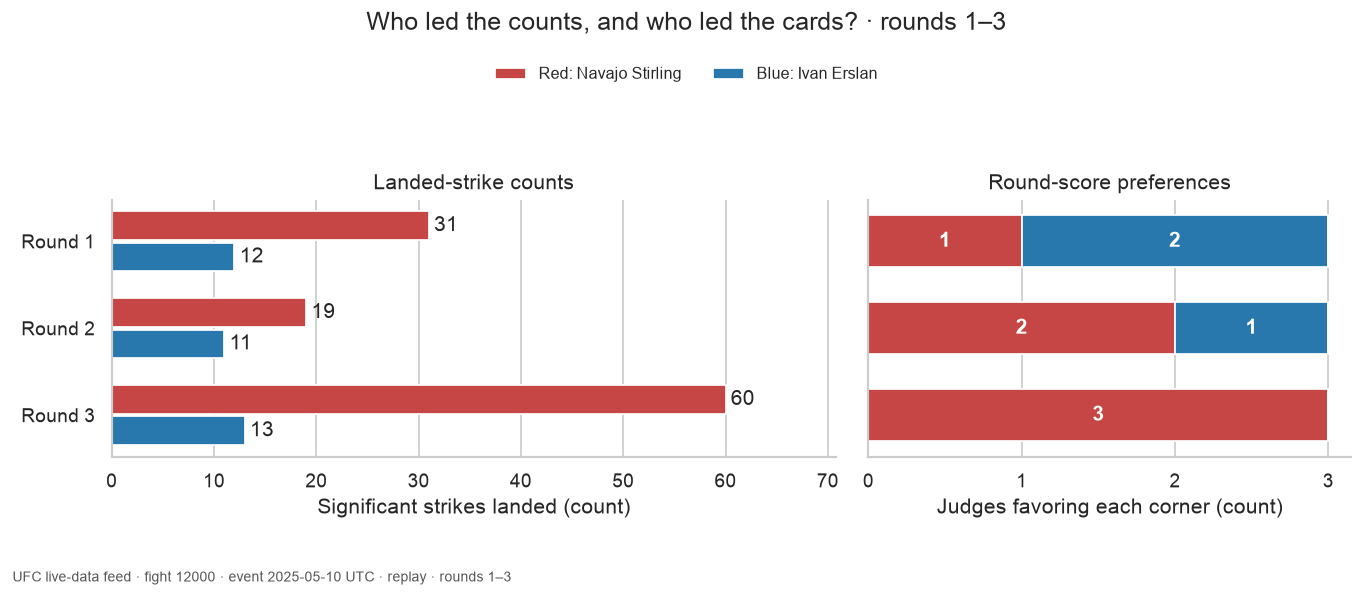

The strike-count leader and majority of judges differ in **1 of 3 selected rounds** (rounds: **1**). These are comparisons of two recorded fields, not a test of whether a judge was correct. The counts do not encode the impact, sequence or full context of the actions, and this one deliberately chosen bout cannot estimate how often disagreement occurs across UFC.

In [8]:
display(rounds)
assert (rounds.red_votes + rounds.blue_votes + rounds.tied_votes == rounds.judges).all()
assert len(rounds) == LAST_ROUND
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), sharey=True, gridspec_kw={"width_ratios": [1.5, 1]})
y = np.arange(len(rounds))
labels = [f"Round {r}" for r in rounds.round_number]
for offset, key, corner in [(-0.18, "red_landed", "Red"), (0.18, "blue_landed", "Blue")]:
    bars = axes[0].barh(
        y + offset,
        rounds[key],
        height=0.33,
        color=colors[corner],
        label=f"{corner}: {red_name if corner == 'Red' else blue_name}",
    )
    axes[0].bar_label(bars, padding=3)
left = np.zeros(len(rounds))
for key, corner in [("red_votes", "Red"), ("blue_votes", "Blue"), ("tied_votes", "Tied")]:
    axes[1].barh(y, rounds[key], left=left, height=0.6, color=colors[corner], label=corner)
    for i, (v, start) in enumerate(zip(rounds[key], left, strict=True)):
        if v:
            axes[1].text(start + v / 2, i, str(v), ha="center", va="center", color="white", fontweight="bold")
    left += rounds[key].to_numpy()
axes[0].set(
    yticks=y,
    yticklabels=labels,
    xlabel="Significant strikes landed (count)",
    xlim=(0, max(rounds.red_landed.max(), rounds.blue_landed.max()) * 1.18),
    title="Landed-strike counts",
)
axes[1].set(
    xlabel="Judges favoring each corner (count)",
    xticks=range(int(rounds.judges.max()) + 1),
    xlim=(0, rounds.judges.max() + 0.15),
    title="Round-score preferences",
)
axes[0].invert_yaxis()
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.91),
    ncol=2,
    fontsize=9,
    frameon=False,
)
for ax in axes:
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Who led the counts, and who led the cards? · rounds 1–{LAST_ROUND}")
finish(fig, top=0.82)
disagreements = rounds[
    (rounds.strike_leader.isin(["Red", "Blue"]))
    & (rounds.majority_corner.isin(["Red", "Blue"]))
    & (rounds.strike_leader != rounds.majority_corner)
]
round_labels = ", ".join(map(str, disagreements.round_number)) or "none"
prose(
    f"The strike-count leader and majority of judges differ in **{len(disagreements)} of {len(rounds)} selected rounds** (rounds: **{round_labels}**). These are comparisons of two recorded fields, not a test of whether a judge was correct. The counts do not encode the impact, sequence or full context of the actions, and this one deliberately chosen bout cannot estimate how often disagreement occurs across UFC."
)

## Keep each judge's points and the final result distinct

Sum awarded points within the selected prefix, keeping judges separate. These are **prefix totals**, not an invented decision rule based on summing judges together. The heatmap uses red-minus-blue point margins and labels every cell with the original red–blue score. Stable symmetric colors preserve direction; a 10–8 round differs from a 10–9 even when both favor red.

We also sum strikes within the same prefix. Accuracy is **sum(landed) / sum(attempted)**, not the unweighted average of round percentages. The final outcome column is explicitly labeled as the recorded full-fight result; it never changes when a local prefix changes.

In [9]:
%%sql cards <<
SELECT judge_id,judge_name,round_number,red_score,blue_score,red_score-blue_score AS margin
FROM selected_scorecards ORDER BY judge_name,round_number;

In [10]:
%%sql totals <<
SELECT r.fighter_id,r.fighter_name,r.corner,count(*) AS selected_rounds,
 sum(r.sig_strikes_landed) AS sig_landed,sum(r.sig_strikes_attempted) AS sig_attempted,
 round(100.0*sum(r.sig_strikes_landed)/nullif(sum(r.sig_strikes_attempted),0),2) AS pooled_accuracy_pct,
 sum(r.control_seconds) AS control_seconds,t.outcome AS recorded_full_fight_outcome
FROM selected_rounds r JOIN fight_totals t USING(fight_id,fighter_id)
GROUP BY r.fighter_id,r.fighter_name,r.corner,t.outcome ORDER BY r.corner DESC;

In [11]:
%%sql point_totals <<
SELECT judge_id,judge_name,sum(red_score) AS red_score,sum(blue_score) AS blue_score,
 CASE WHEN sum(red_score)>sum(blue_score) THEN 'Red'
      WHEN sum(red_score)<sum(blue_score) THEN 'Blue' ELSE 'Tied' END AS prefix_leader
FROM selected_scorecards GROUP BY judge_id,judge_name ORDER BY judge_name;

,fighter_id,fighter_name,corner,selected_rounds,sig_landed,sig_attempted,pooled_accuracy_pct,control_seconds,recorded_full_fight_outcome
0,4252,Navajo Stirling,Red,3,110.0,225.0,48.89,181.0,Win
1,4271,Ivan Erslan,Blue,3,36.0,100.0,36.00,101.0,Loss


,judge_id,judge_name,red_score,blue_score,prefix_leader
0,32,Eric Colon,29.0,28.0,Red
1,541,Guy Girard,29.0,28.0,Red
2,228,Mike Bell,29.0,27.0,Red


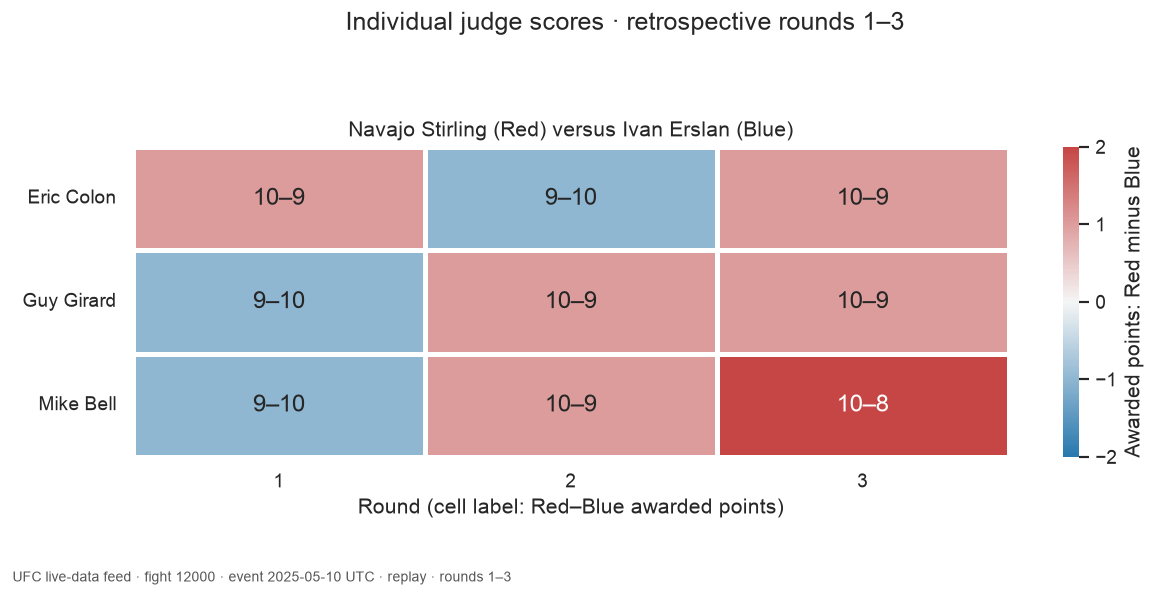

Across rounds **1–3**, significant strikes total **110 red versus 36 blue**. Separate judge-prefix totals favor red on **3 cards**, blue on **0**, with **0 tied**. The recorded complete-fight result remains **Navajo Stirling — Decision - Unanimous**. Prefix scores are hindsight summaries; do not relabel them as the result of a shortened fight. A point margin is an awarded score, not a measurement of strike impact.

4080

In [12]:
display(totals)
display(point_totals)
margins = cards.pivot(index="judge_name", columns="round_number", values="margin")
annotations = cards.assign(score=cards.red_score.astype(str) + "–" + cards.blue_score.astype(str)).pivot(
    index="judge_name", columns="round_number", values="score"
)
full_margins = frames["all_scorecards"].red_score - frames["all_scorecards"].blue_score
extent = max(1, int(full_margins.abs().max()))
cmap = LinearSegmentedColormap.from_list("corners", [colors["Blue"], "#f5f5f5", colors["Red"]])
fig, ax = plt.subplots(figsize=(10, 4.7))
sns.heatmap(
    margins,
    annot=annotations,
    fmt="",
    cmap=cmap,
    vmin=-extent,
    vmax=extent,
    center=0,
    linewidths=2,
    linecolor="white",
    ax=ax,
    cbar_kws={"label": "Awarded points: Red minus Blue", "ticks": list(range(-extent, extent + 1))},
    annot_kws={"fontsize": 14},
)
ax.set(
    xlabel="Round (cell label: Red–Blue awarded points)",
    ylabel="",
    title=f"{red_name} (Red) versus {blue_name} (Blue)",
)
ax.tick_params(axis="y", rotation=0)
fig.suptitle(f"Individual judge scores · retrospective rounds 1–{LAST_ROUND}")
finish(fig)
red_total = int(totals.loc[totals.corner.eq("Red"), "sig_landed"].iloc[0])
blue_total = int(totals.loc[totals.corner.eq("Blue"), "sig_landed"].iloc[0])
red_cards = int(point_totals.prefix_leader.eq("Red").sum())
blue_cards = int(point_totals.prefix_leader.eq("Blue").sum())
tied_cards = int(point_totals.prefix_leader.eq("Tied").sum())
final_winner = frames["fight_totals"].loc[frames["fight_totals"].outcome.eq("Win"), "fighter_name"].tolist()
prose(
    f"Across rounds **1–{LAST_ROUND}**, significant strikes total **{red_total} red versus {blue_total} blue**. Separate judge-prefix totals favor red on **{red_cards} cards**, blue on **{blue_cards}**, with **{tied_cards} tied**. The recorded complete-fight result remains **{', '.join(final_winner)} — {payload['Result']['Method']}**. Prefix scores are hindsight summaries; do not relabel them as the result of a shortened fight. A point margin is an awarded score, not a measurement of strike impact."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "last_round": LAST_ROUND,
            "mode": DATA_MODE,
            "run_utc": run_utc,
            "fingerprint": fingerprint,
            "rounds": rounds.to_dict(orient="records"),
            "totals": json.loads(totals.to_json(orient="records")),
            "cards": cards.to_dict(orient="records"),
            "point_totals": point_totals.to_dict(orient="records"),
            "checks": checks.to_dict(orient="records"),
            "requests": audit,
            "source_receipt_utc": source_time,
        },
        indent=2,
    )
)

## Experiment: stop the descriptive window after round one

Change only `LAST_ROUND` from **3 to 1**, keeping replay mode. Predict that the round-two and round-three bars and score cells disappear. Compare the remaining strike counts, each judge's prefix leader and the unchanged full-fight outcome. Does a first-round strike advantage imply the same majority preference? The full-source fingerprint, response SHA256, all ledger checks and **one-read budget** must stay identical. Restore **3** afterwards.

This selected historical example supports a careful distinction between counting actions and reading scorecards. It does not evaluate judging accuracy, establish a scoring model, rank fighter ability, or predict future results. Source revisions in live mode are shown with new receipt times and hashes; failed or incomplete responses stop the run.

In [13]:
con.close()
api.close()
secret_directory.cleanup()
for key, value in previous.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)